N= 2 | F = 1.605228e-01 | F^(1/N) = 0.400653
N= 3 | F = 6.431391e-02 | F^(1/N) = 0.400653
N= 4 | F = 2.576755e-02 | F^(1/N) = 0.400653
N= 5 | F = 1.032385e-02 | F^(1/N) = 0.400653
N= 6 | F = 4.136279e-03 | F^(1/N) = 0.400653
N= 7 | F = 1.657212e-03 | F^(1/N) = 0.400653
N= 8 | F = 6.639668e-04 | F^(1/N) = 0.400653
N=10 | F = 1.065818e-04 | F^(1/N) = 0.400653


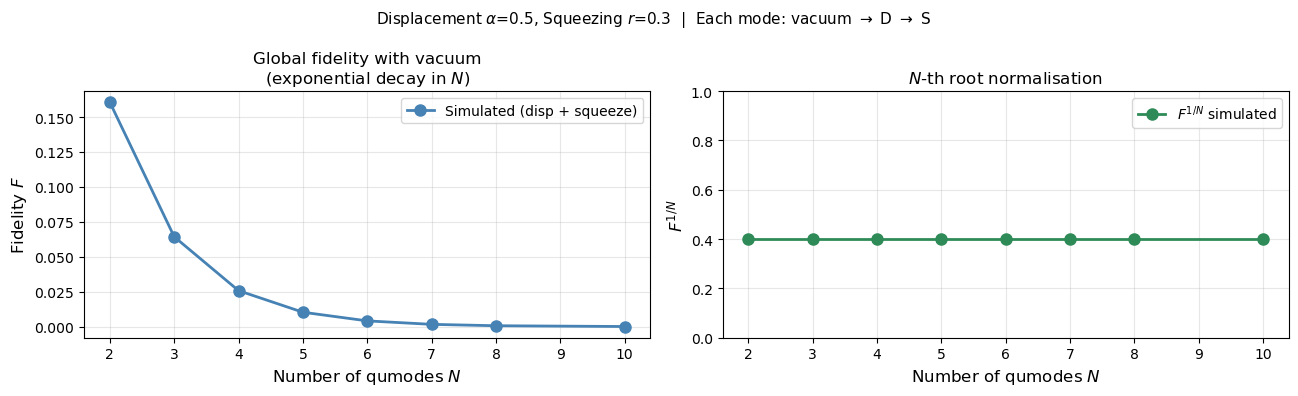

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ── Fixed operation parameters ───────────────────────────────────────────────
DISPLACEMENT = 0.5
SQUEEZING    = 0.3
hbar = 2.0

def vacuum_state_torch_batch(num_wires, batch_size):
    """
    Returns batched vacuum state.
    cov: (B, 2N, 2N), mu: (B, 2N)
    """
    mu = torch.zeros(batch_size, 2 * num_wires, dtype=torch.float64)
    cov = (
        (torch.eye(2 * num_wires, dtype=torch.float64) * hbar / 2)
        .unsqueeze(0)
        .expand(batch_size, -1, -1)
        .clone()
    )
    return cov, mu

def displacement_torch_batch(state, wire, alpha_real, alpha_imag, num_wires):
    """
    alpha_real, alpha_imag: (B,) — per-sample displacements.
    Displacement only shifts means; cov is unchanged.
    """
    cov, mu = state
    N = num_wires
    dx = alpha_real * (2 * hbar) ** 0.5  # (B,)
    dp = alpha_imag * (2 * hbar) ** 0.5  # (B,)

    mu = mu.clone()
    mu[:, wire] = mu[:, wire] + dx
    mu[:, wire + N] = mu[:, wire + N] + dp
    return cov, mu

def squeezing_torch_batch(state, wire, r, phi, num_wires):
    """
    r, phi: (B,) — per-sample squeezing params.
    Builds a batched (B, 2, 2) symplectic and delegates to apply_symplectic_batch.
    """
    cp, sp = torch.cos(phi), torch.sin(phi)  # (B,)
    ch, sh = torch.cosh(r), torch.sinh(r)  # (B,)
    # Stack into (B, 2, 2)
    row0 = torch.stack([ch - cp * sh, -sp * sh], dim=-1)  # (B, 2)
    row1 = torch.stack([-sp * sh, ch + cp * sh], dim=-1)  # (B, 2)
    S = torch.stack([row0, row1], dim=1)  # (B, 2, 2)
    return apply_symplectic_batch(state, S, [wire], num_wires)

def apply_symplectic_batch(state, S, wires, num_wires):
    """
    Apply a symplectic matrix S (acting on `wires`) to a batched state.
    S: (2k, 2k) — shared across batch (e.g. BS, rotation layers)
       OR (B, 2k, 2k) — per-sample (e.g. data-dependent squeezing)
    cov: (B, 2N, 2N), mu: (B, 2N)
    """
    cov, mu = state
    B = mu.shape[0]
    N = num_wires
    w = list(wires)

    wx = torch.tensor(w, dtype=torch.long)
    wp = torch.tensor([wi + N for wi in w], dtype=torch.long)
    idx = torch.cat([wx, wp])  # length 2k

    # Build full S2: (2N, 2N) or (B, 2N, 2N) depending on whether S is batched
    if S.dim() == 2:
        # Shared symplectic — broadcast over batch
        S2 = torch.eye(2 * N, dtype=torch.float64)
        S2[idx.unsqueeze(1), idx.unsqueeze(0)] = S
        # cov: (B, 2N, 2N); S2: (2N, 2N) → broadcast
        cov_new = S2 @ cov @ S2.T  # (B, 2N, 2N)
        mu_new = (S2 @ mu.unsqueeze(-1)).squeeze(-1)  # (B, 2N)
    else:
        # Per-sample symplectic: S shape (B, 2k, 2k)
        S2 = (
            torch.eye(2 * N, dtype=torch.float64).unsqueeze(0).expand(B, -1, -1).clone()
        )
        row_idx = idx.unsqueeze(1).expand(B, -1, idx.shape[0])  # (B, 2k, 2k)
        col_idx = idx.unsqueeze(0).expand(B, idx.shape[0], -1)  # (B, 2k, 2k)
        batch_idx = (
            torch.arange(B, dtype=torch.long)
            .unsqueeze(1)
            .unsqueeze(2)
            .expand(B, idx.shape[0], idx.shape[0])
        )
        S2 = S2.clone()
        S2[batch_idx, row_idx, col_idx] = S
        # Batched matmul: (B, 2N, 2N)
        cov_new = torch.bmm(torch.bmm(S2, cov), S2.transpose(1, 2))
        mu_new = torch.bmm(S2, mu.unsqueeze(-1)).squeeze(-1)

    return cov_new, mu_new

def beamsplitter_torch_batch(state, wire1, wire2, theta, phi, num_wires):
    """
    theta, phi: scalar tensors — shared across batch.
    """
    cp, sp = torch.cos(phi), torch.sin(phi)
    ct, st = torch.cos(theta), torch.sin(theta)
    Z = torch.zeros((), dtype=torch.float64)
    S = torch.stack(
        [
            torch.stack([ct, -cp * st, Z, -st * sp]),
            torch.stack([cp * st, ct, -st * sp, Z]),
            torch.stack([Z, st * sp, ct, -cp * st]),
            torch.stack([st * sp, Z, cp * st, ct]),
        ]
    )  # (4, 4)
    return apply_symplectic_batch(state, S, [wire1, wire2], num_wires)
# ── Fidelity with vacuum (hbar=2 convention, matching your code) ─────────────
def fidelity_with_vacuum(cov, mu):
    """
    cov: (2N, 2N), mu: (2N)  — single state, no batch dim
    Uses hbar=2 convention (matching vacuum_state_torch_batch).
    Vacuum: cov_1 = I, mu_1 = 0
    """
    N2      = mu.shape[0]
    cov_1   = torch.eye(N2, dtype=torch.float64)          # hbar=2 vacuum cov
    mu_1    = torch.zeros(N2, dtype=torch.float64)

    # Banchi formula — no /2 rescaling needed since we stay in hbar=2 throughout
    cov_sum = cov + cov_1                                  # (2N, 2N)
    F0      = torch.linalg.det(cov_sum).pow(-0.25)        # scalar
    inv     = torch.linalg.inv(cov_sum)
    d       = (mu - mu_1).unsqueeze(-1)                   # (2N, 1)
    expnt   = -0.25 * (d.T @ inv @ d).squeeze()           # scalar
    F       = (F0 * torch.exp(expnt)) ** 2

    return F.item()


# ── Build state for N modes: vacuum → displace → squeeze each mode ───────────
def build_state(N):
    """
    Starts from vacuum, applies fixed displacement and squeezing
    to every mode. Returns (cov, mu) with batch dim squeezed out.
    """
    B     = 1
    state = vacuum_state_torch_batch(N, B)

    ZERO  = torch.zeros(B, dtype=torch.float64)
    D_VAL = torch.full((B,), DISPLACEMENT, dtype=torch.float64)
    S_VAL = torch.full((B,), SQUEEZING,    dtype=torch.float64)
    PHI   = torch.zeros(B, dtype=torch.float64)

    for wire in range(N):
        state = displacement_torch_batch(state, wire, D_VAL, ZERO, N)
        state = squeezing_torch_batch(state, wire, S_VAL, PHI, N)

    cov, mu = state
    return cov[0], mu[0]   # drop batch dim → (2N, 2N), (2N)


# ── Sweep over N ─────────────────────────────────────────────────────────────
N_values  = [2, 3, 4, 5, 6, 7, 8, 10]
F_values  = []
Fn_values = []

for N in N_values:
    cov, mu = build_state(N)
    F        = fidelity_with_vacuum(cov, mu)
    Fn       = F ** (1.0 / N)
    F_values.append(F)
    Fn_values.append(Fn)
    print(f"N={N:2d} | F = {F:.6e} | F^(1/N) = {Fn:.6f}")


# ── Theoretical reference (pure displacement only, no squeezing) ─────────────
# For hbar=2: F_1 = exp(-alpha^2) where alpha = DISPLACEMENT
# So F_N = exp(-N * DISPLACEMENT^2)
N_theory = np.linspace(2, 10, 200)
F_theory = np.exp(-N_theory * DISPLACEMENT**2)


# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- Left: raw F (log scale) ---
axes[0].plot(N_values, F_values, "o-", color="steelblue",
             linewidth=2, markersize=8, label="Simulated (disp + squeeze)")
axes[0].set_xlabel("Number of qumodes $N$", fontsize=12)
axes[0].set_ylabel("Fidelity $F$", fontsize=12)
axes[0].set_title("Global fidelity with vacuum\n(exponential decay in $N$)", fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)

# --- Right: N-th root ---
axes[1].plot(N_values, Fn_values, "o-", color="seagreen",
             linewidth=2, markersize=8, label=r"$F^{1/N}$ simulated")
axes[1].set_xlabel("Number of qumodes $N$", fontsize=12)
axes[1].set_ylabel(r"$F^{1/N}$", fontsize=12)
axes[1].set_title(r"$N$-th root normalisation", fontsize=12)
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

fig.suptitle(
    rf"Displacement $\alpha$={DISPLACEMENT}, Squeezing $r$={SQUEEZING}  |  "
    r"Each mode: vacuum $\rightarrow$ D $\rightarrow$ S",
    fontsize=11
)
plt.tight_layout()
plt.savefig("fidelity_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

# Max N vs Mean N

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
my_cmap = [
    "#FF7165",
    "#9B6DFF",
    "#E5C04A",
    "#dc267f",
    "#78C2EC",
    "#2A9D55",
    "#4A2FE2" 
]

# Path to CSV
path = "/vols/cms/lgc124/QMLoutputs/quantum_scan_logs/2026-08-17/comparison_NoRescaling/code_snapshot/outputs/2026-08-17/scan:(comparison_NoRescaling)/8:Q:Done/Q_logging.csv"

# Load
df = pd.read_csv(path)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df["epoch"],
    df["meanN"],
    marker="o",
    linewidth=2,
    label="Mean N",
    color=my_cmap[1]
)

ax.plot(
    df["maxN"],
    marker="o",
    linewidth=2,
    label="Max N",
    color=my_cmap[0]
)

ax.set_xlabel("Epoch")
ax.set_ylabel("N")
ax.set_title("No Rescaling")
ax.grid(alpha=0.3)
ax.set_yscale("log")
ax.legend()

plt.tight_layout()
plt.show()

# High Variance Check

In [ ]:
import os
import re
import ast
import yaml
import math
import numpy as np
import pandas as pd

# ============================================================
# Settings
# ============================================================

ROOT_DIR = "/vols/cms/lgc124/QMLoutputs/quantum_scan_logs/2026-08-21/new_enc_clamp_test/code_snapshot/outputs"  # <-- change this

TOL = 1e-4  # how close to a bound counts as "stuck"

PARAM_BOUNDS = {
    "enc_var_pt": (0.0, 2.0),
    "enc_var_eta": (0.0, 2.0),
    "enc_var_phi": (0.0, 2.0),
    "enc_s_phi": None,
    "bs_theta": (0.0, math.pi / 2),
    "bs_phi": None,
    "lg_r_phi": None,
    "lg_s_r": (0.0, 2.0),
    "lg_s_phi": None,
    "lg_disp_real": (-2.0, 2.0),
    "lg_disp_imag": (-2.0, 2.0),
}


# ============================================================
# Parsing helpers
# ============================================================

def parse_best_params(path):
    params = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("==="):
                continue
            if ":" not in line:
                continue
            name, value_str = line.split(":", 1)
            name = name.strip()
            value_str = value_str.strip()
            try:
                value = ast.literal_eval(value_str)
            except (ValueError, SyntaxError):
                continue
            if isinstance(value, (int, float)):
                value = [float(value)]
            elif isinstance(value, (list, tuple)):
                value = [float(v) for v in value]
            else:
                continue
            params[name] = value
    return params


def load_yaml(path):
    with open(path, "r") as f:
        return yaml.safe_load(f)


def find_run_dirs(root_dir):
    run_dirs = []
    for dirpath, _, filenames in os.walk(root_dir):
        needed = {"summary.yml", "configUsed.yml", "best_params.txt"}
        if needed.issubset(set(filenames)):
            run_dirs.append(dirpath)
    return run_dirs


# ============================================================
# Stuck-at-bound check
# ============================================================

def check_stuck(params, bounds=PARAM_BOUNDS, tol=TOL):
    stuck_details = {}
    n_stuck = 0
    n_total = 0

    for name, values in params.items():
        if name not in bounds:
            continue
        b = bounds[name]
        if b is None:
            continue
        low, high = b

        flags = [
            (v <= low + tol) or (v >= high - tol)
            for v in values
        ]
        stuck_details[name] = flags
        n_stuck += sum(flags)
        n_total += len(flags)

    return stuck_details, n_stuck, n_total


# ============================================================
# Main scan
# ============================================================

def scan_all_runs(root_dir):
    rows = []
    run_dirs = find_run_dirs(root_dir)

    print(f"Found {len(run_dirs)} run directories with required files.")

    for d in run_dirs:
        try:
            summary = load_yaml(os.path.join(d, "summary.yml"))
            config = load_yaml(os.path.join(d, "configUsed.yml"))
            params = parse_best_params(os.path.join(d, "best_params.txt"))
        except Exception as e:
            print(f"Skipping {d}: failed to load ({e})")
            continue

        auc = summary.get("Best_auc_score", None)
        circuit_cfg = config.get("circuit", {})
        wires = circuit_cfg.get("wires", None)
        substrate = circuit_cfg.get("bs_substrate_type", None)

        stuck_details, n_stuck, n_total = check_stuck(params)
        stuck_names = [name for name, flags in stuck_details.items() if any(flags)]

        rows.append({
            "dir": d,
            "wires": wires,
            "substrate": substrate,
            "auc": auc,
            "n_stuck": n_stuck,
            "n_total": n_total,
            "frac_stuck": (n_stuck / n_total) if n_total > 0 else np.nan,
            "any_stuck": n_stuck > 0,
            "stuck_param_names": ", ".join(stuck_names) if stuck_names else "",
        })

    return pd.DataFrame(rows)


# ============================================================
# Run it
# ============================================================

df = scan_all_runs(ROOT_DIR)
df = df.sort_values(["substrate", "wires", "auc"]).reset_index(drop=True)
df

In [ ]:
# Stuck rate by substrate and wires
df.groupby(["substrate", "wires"])["any_stuck"].agg(["mean", "sum", "count"])

In [ ]:
print("Negative means 'stuck' correlates to worse AUC: \n")
for param_name in PARAM_BOUNDS:
    if PARAM_BOUNDS[param_name] is None:
        continue
    df[f"stuck_{param_name}"] = df["stuck_param_names"].str.contains(param_name, na=False)
    sub = df.dropna(subset=["auc"])
    if sub[f"stuck_{param_name}"].sum() > 5:
        r, p = spearmanr(sub[f"stuck_{param_name}"].astype(int), sub["auc"])
        print(f"{param_name}: r={r:.3f}, p={p:.4f}, n_stuck={sub[f'stuck_{param_name}'].sum()}")

# Squeeze Funcs

In [2]:
import torch
hbar = 2.0

def squeezing_torch_batch_new(state, wire, z_real, z_imag, num_wires):
    """
    Batched squeezing using Cartesian squeezing parameters.

    z_real, z_imag: (B,)

    The squeezing symplectic is constructed as a matrix exponential,
    avoiding the singular Cartesian -> polar conversion at z = 0.
    """

    # Construct the squeezing generator K directly from (z_real, z_imag). This avoids the
    # singular polar conversion to (r, phi). Also, since K^2 = (z_real^2 + z_imag^2) I,
    # exp(K) analytically produces the required cosh(r)/sinh(r) squeezing terms,
    # while matrix_exp differentiates directly through z_real and z_imag, including at (0,0),
    # without explicitly computing r via sqrt. Therefore no backprop issues.

    K = torch.stack([
        torch.stack([-z_real, -z_imag], dim=-1),
        torch.stack([-z_imag,  z_real], dim=-1),
    ], dim=1)

    # (B, 2, 2)
    S = torch.linalg.matrix_exp(K)

    if not torch.isfinite(S).all():
        raise RuntimeError(
            f"S contains NaN/Inf: "
            f"z_real={z_real}, z_imag={z_imag}"
        )

    return apply_symplectic_batch(state, S, [wire], num_wires)

def squeezing_torch_batch(state, wire, z_real, z_imag, num_wires):
    """
    r, phi: (B,) — per-sample squeezing params.
    Builds a batched (B, 2, 2) symplectic and delegates to apply_symplectic_batch.
    """
    r = torch.sqrt(z_real**2 + z_imag**2)          # (B,)
    phi = torch.atan2(z_imag, z_real)               # (B,)

    cp, sp = torch.cos(phi), torch.sin(phi)  # (B,)
    ch, sh = torch.cosh(r), torch.sinh(r)  # (B,)
    # Stack into (B, 2, 2)
    row0 = torch.stack([ch - cp * sh, -sp * sh], dim=-1)  # (B, 2)
    row1 = torch.stack([-sp * sh, ch + cp * sh], dim=-1)  # (B, 2)
    S = torch.stack([row0, row1], dim=1)  # (B, 2, 2)

    return apply_symplectic_batch(state, S, [wire], num_wires)

###############################################################################################

def vacuum_state_torch_batch(num_wires, batch_size):
    """
    Returns batched vacuum state.
    cov: (B, 2N, 2N), mu: (B, 2N)
    """
    mu = torch.zeros(batch_size, 2 * num_wires, dtype=torch.float64)
    cov = ((torch.eye(2 * num_wires, dtype=torch.float64) * hbar /
           2).unsqueeze(0).expand(batch_size, -1, -1).clone())
    return cov, mu


def apply_symplectic_batch(state, S, wires, num_wires):
    """
    Apply a symplectic matrix S (acting on `wires`) to a batched state.
    S: (2k, 2k) — shared across batch (e.g. BS, rotation layers)
       OR (B, 2k, 2k) — per-sample (e.g. data-dependent squeezing)
    cov: (B, 2N, 2N), mu: (B, 2N)
    """
    cov, mu = state
    B = mu.shape[0]
    N = num_wires
    w = list(wires)

    wx = torch.tensor(w, dtype=torch.long)
    wp = torch.tensor([wi + N for wi in w], dtype=torch.long)
    idx = torch.cat([wx, wp])  # length 2k

    # Build full S2: (2N, 2N) or (B, 2N, 2N) depending on whether S is batched
    if S.dim() == 2:
        # Shared symplectic — broadcast over batch
        S2 = torch.eye(2 * N, dtype=torch.float64)
        S2[idx.unsqueeze(1), idx.unsqueeze(0)] = S
        # cov: (B, 2N, 2N); S2: (2N, 2N) → broadcast
        cov_new = S2 @ cov @ S2.T  # (B, 2N, 2N)
        mu_new = (S2 @ mu.unsqueeze(-1)).squeeze(-1)  # (B, 2N)
    else:
        # Per-sample symplectic: S shape (B, 2k, 2k)
        S2 = (torch.eye(2 * N, dtype=torch.float64).unsqueeze(0).expand(B, -1, -1).clone())
        row_idx = idx.unsqueeze(1).expand(B, -1, idx.shape[0])  # (B, 2k, 2k)
        col_idx = idx.unsqueeze(0).expand(B, idx.shape[0], -1)  # (B, 2k, 2k)
        batch_idx = (torch.arange(B, dtype=torch.long).unsqueeze(
            1).unsqueeze(2).expand(B, idx.shape[0], idx.shape[0]))
        S2 = S2.clone()
        S2[batch_idx, row_idx, col_idx] = S
        # Batched matmul: (B, 2N, 2N)
        cov_new = torch.bmm(torch.bmm(S2, cov), S2.transpose(1, 2))
        mu_new = torch.bmm(S2, mu.unsqueeze(-1)).squeeze(-1)

    return cov_new, mu_new


def displacement_torch_batch(state, wire, alpha_real, alpha_imag, num_wires):
    """
    alpha_real, alpha_imag: (B,) — per-sample displacements.
    Displacement only shifts means; cov is unchanged.
    """
    cov, mu = state
    N = num_wires
    dx = alpha_real * (2 * hbar) ** 0.5  # (B,)
    dp = alpha_imag * (2 * hbar) ** 0.5  # (B,)

    mu = mu.clone()
    mu[:, wire] = mu[:, wire] + dx
    mu[:, wire + N] = mu[:, wire + N] + dp
    return cov, mu

###########################################################################################################################
    
state = vacuum_state_torch_batch(3,1)
state_base = displacement_torch_batch(state,0,torch.tensor(2.0, dtype=torch.float64),torch.tensor(2.0, dtype=torch.float64),3)
state_old = squeezing_torch_batch(state_base,0,torch.tensor(1.3, dtype=torch.float64),torch.tensor(1.0, dtype=torch.float64),3)
state_new = squeezing_torch_batch_new(state_base,0,torch.tensor(1.3, dtype=torch.float64),torch.tensor(1.0, dtype=torch.float64),3)
print(state_old)
print("")
print(state_new)

(tensor([[[ 2.7900,  0.0000,  0.0000, -8.0923,  0.0000,  0.0000],
         [ 0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
         [-8.0923,  0.0000,  0.0000, 23.8299,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000]]],
       dtype=torch.float64), tensor([[-3.2168,  0.0000,  0.0000, 12.5147,  0.0000,  0.0000]],
       dtype=torch.float64))

(tensor([[[ 2.7900,  0.0000,  0.0000, -8.0923,  0.0000,  0.0000],
         [ 0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
         [-8.0923,  0.0000,  0.0000, 23.8299,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000]]],
       dtype=torch.float64), tensor([[-3.2168,  0.0000,  0.0000, 12.5147,  0.0000,  0.0000

# Wigner

In [3]:
state = vacuum_state_torch_batch(1,1)
vacuum_cov,vacuum_mu = state

state2 = displacement_torch_batch(state,0,torch.tensor(1.2, dtype=torch.float64),torch.tensor(0, dtype=torch.float64),1)
disp_cov, disp_mu = state2
print(disp_mu)

state3 = squeezing_torch_batch(state,0,torch.tensor(0.5, dtype=torch.float64),torch.tensor(0, dtype=torch.float64),1)
squeeze_cov, squeeze_mu = state3
print(squeeze_mu)

tensor([[2.4000, 0.0000]], dtype=torch.float64)
tensor([[0., 0.]], dtype=torch.float64)


/tmp/ipykernel_152887/720466272.py:101: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  ax = fig.add_subplot(n, 1, i + 1, projection="3d")


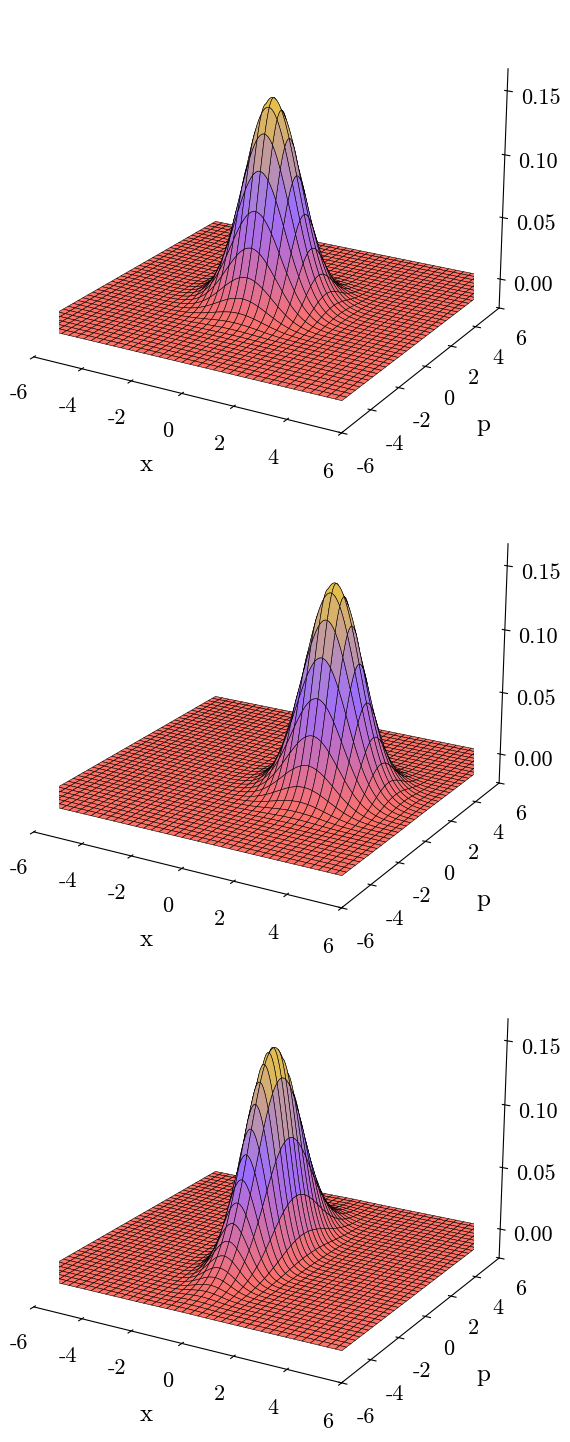

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman"],
    "axes.unicode_minus": False,
})

my_cmap = ["#FF7165", "#9B6DFF", "#E5C04A"]
CMAP = LinearSegmentedColormap.from_list("my_cmap_continuous", my_cmap, N=256)


def _to_numpy(a):
    if hasattr(a, "detach"):
        a = a.detach().cpu().numpy()
    return np.asarray(a, dtype=float)


def _wigner_grid(mu, cov, x_range, p_range, n_points):
    mu_x, mu_p = mu[0], mu[1]
    x = np.linspace(*x_range, n_points)
    p = np.linspace(*p_range, n_points)
    X, P = np.meshgrid(x, p)

    inv_cov = np.linalg.inv(cov)
    det_cov = np.linalg.det(cov)
    dx, dp = X - mu_x, P - mu_p
    a, b, c, d = inv_cov[0, 0], inv_cov[0, 1], inv_cov[1, 0], inv_cov[1, 1]
    quad = a * dx**2 + (b + c) * dx * dp + d * dp**2
    W = np.exp(-0.5 * quad) / (2 * np.pi * np.sqrt(det_cov))
    return X, P, W


def _plot_wigner_on_ax(ax, X, P, W, z_floor, z_top, elev, azim, cmap, x_lim, p_lim):
    n_points = X.shape[0]
    stride = max(1, n_points // 40)
    ax.plot_surface(
        X, P, W, cmap=cmap,
        rstride=stride, cstride=stride,
        linewidth=0.4, edgecolor="black",
        antialiased=True, alpha=1,
    )

    ax.contour(X, P, W, zdir="z", offset=z_floor, cmap=cmap, levels=10, linewidths=1.2)

    ax.set_xlim(*x_lim)
    ax.set_ylim(*p_lim)
    ax.set_zlim(z_floor, z_top)

    ax.set_xlabel("x", fontsize=18, labelpad=8)
    ax.set_ylabel("p", fontsize=18, labelpad=8)
    ax.set_zlabel("W(x, p)", fontsize=18, labelpad=10)
    ax.view_init(elev=elev, azim=azim)

    ax.tick_params(axis="x", labelsize=16)
    ax.tick_params(axis="y", labelsize=16)
    ax.tick_params(axis="z", labelsize=16)

    ax.set_box_aspect(None, zoom=1.3)

    ax.grid(False)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_visible(False)
        axis.pane.fill = False


def plot_wigner_stack(states, elev=20, azim=-60, n_points=200, k=5, cmap=CMAP, figsize=(5, 20)):
    """
    states: list of (mu, cov) tuples, plotted top-to-bottom, all on shared axes/floor.
    """
    mus = [_to_numpy(mu).reshape(-1) for mu, _ in states]
    covs = [_to_numpy(cov).squeeze() for _, cov in states]

    for mu, cov in zip(mus, covs):
        if mu.size != 2:
            raise ValueError(f"Expected mu to contain exactly 2 values, got {mu.shape}.")
        if cov.shape != (2, 2):
            raise ValueError(f"Expected cov shape (2, 2), got {cov.shape}.")

    # --- Compute a shared x/p range covering all states ---
    x_range = (-6, 6)
    p_range = (-6, 6)

    # --- Precompute all Wigner grids on the shared range ---
    grids = [_wigner_grid(mu, cov, x_range, p_range, n_points) for mu, cov in zip(mus, covs)]

    # --- Shared z floor/top across all panels ---
    w_min = min(W.min() for _, _, W in grids)
    w_max = max(W.max() for _, _, W in grids)
    z_floor = w_min - 0.15 * (w_max - w_min)
    z_top = w_max * 1.05

    fig = plt.figure(figsize=figsize)
    n = len(states)
    for i, (X, P, W) in enumerate(grids):
        ax = fig.add_subplot(n, 1, i + 1, projection="3d")
        _plot_wigner_on_ax(ax, X, P, W, z_floor, z_top, elev, azim, cmap, x_range, p_range)

    fig.subplots_adjust(left=0.02, right=0.85, bottom=0.03, top=0.98, hspace=-0.5)
    plt.show()
    return fig


# --- Example usage: vacuum, displaced, squeezed vacuum ---
hbar = 2.0

states = [
    (vacuum_mu, vacuum_cov),
    (disp_mu, disp_cov),
    (squeeze_mu, squeeze_cov),
]

_ = plot_wigner_stack(states)

# Output AUC

In [4]:
import numpy as np
from sklearn.metrics import roc_auc_score

path = "/home/hep/lgc124/PhDCode/LXAutoQML/AutoQML/outputs/2026-09-26/14-25-54:(43da5):QB:Done/QB_evaluations.npz"
f = np.load(path)
print(roc_auc_score(f["y_true"],f["losses"]))

0.8621572799999999


(0.8, 0.9)

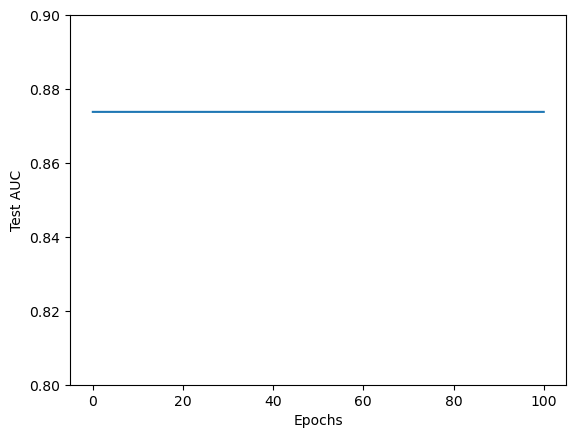

In [23]:
import yaml
import matplotlib.pyplot as plt

with open("/home/hep/lgc124/PhDCode/LXAutoQML/AutoQML/outputs/2026-09-28/10-51-51:(3d688):QB:Done/summary.yml") as f:
    summary = yaml.safe_load(f)

aucs = summary["aucs"]

plt.figure()
plt.plot(range(len(aucs)),aucs)
plt.xlabel("Epochs")
plt.ylabel("Test AUC")
plt.ylim([0.8,0.9])

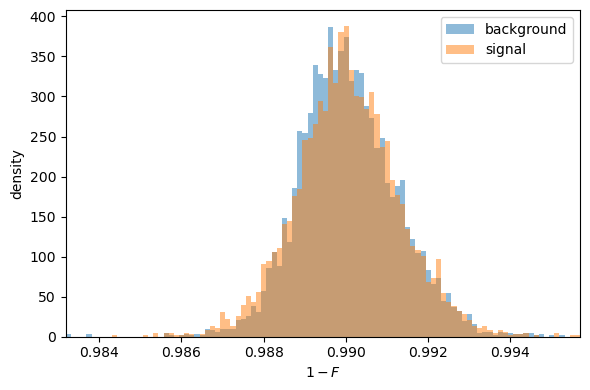

In [26]:
import numpy as np
import matplotlib.pyplot as plt

def plot_loss_hist(npz_path, bins=100, logy=False, save_path=None):
    data = np.load(npz_path)
    losses = data["losses"]
    y = data["y_true"]

    edges = np.linspace(losses.min(), losses.max(), bins + 1)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(losses[y == 0], bins=edges, alpha=0.5, density=True, label="background")
    ax.hist(losses[y == 1], bins=edges, alpha=0.5, density=True, label="signal")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel(r"$1 - F$")
    ax.set_ylabel("density")
    if logy:
        ax.set_yscale("log")
    ax.legend()
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()

plot_loss_hist("/home/hep/lgc124/PhDCode/LXAutoQML/AutoQML/outputs/2026-09-28/11-48-26:(b936e):Q:Done/Q_evaluations.npz")

# CX Gate Check

In [60]:
def cv_cx_torch_batch(state, wire1, wire2, s, num_wires):
    """
    Batched CV CX (SUM) gate, matching the style of beamsplitter_torch_batch.

    state : torch.Tensor, shape (batch, 2 * num_wires)
    wire1 : int, control wire (i)
    wire2 : int, target wire (j)
    s     : scalar tensor -- shared across batch (gate strength / addition parameter)
    num_wires : int, total number of wires N
    """
    one = torch.ones_like(s)
    zero = torch.zeros_like(s)

    S = torch.stack(
        [torch.stack([one, zero, zero, zero]),
         torch.stack([s,   one,  zero, zero]),
         torch.stack([zero, zero, one,  -s]),
         torch.stack([zero, zero, zero, one]),]
    )  # (4, 4)

    return apply_symplectic_batch(state, S, [wire1, wire2], num_wires)

state = vacuum_state_torch_batch(2,1)
state = displacement_torch_batch(state, 0, torch.tensor(1.0, dtype=torch.float64),torch.tensor(0.0, dtype=torch.float64),2)
state = displacement_torch_batch(state, 1, torch.tensor(0.0, dtype=torch.float64),torch.tensor(2.0, dtype=torch.float64),2)
state = cv_cx_torch_batch(state, 0, 1, torch.tensor(2.0, dtype=torch.float64), 2)
print(state)

############################################################################
################################################################## PENNYLANE
############################################################################

import pennylane as qml

dev = qml.device("default.gaussian", wires=2, hbar=2)

@qml.qnode(dev)
def circuit():
    qml.Displacement(1.0, 0.0, wires=0)
    qml.Displacement(2.0, np.pi/2, wires=1)
    qml.ControlledAddition(2.0, wires=[0, 1])
    return qml.expval(qml.QuadX(1))

print(circuit())      # 2.0
print(dev._state)     # means and covariance of the whole state

(tensor([[[ 1.,  2.,  0.,  0.],
         [ 2.,  5.,  0.,  0.],
         [ 0.,  0.,  5., -2.],
         [ 0.,  0., -2.,  1.]]], dtype=torch.float64), tensor([[ 2.,  4., -8.,  4.]], dtype=torch.float64))
4.0
[array([[ 1.,  2.,  0.,  0.],
       [ 2.,  5.,  0.,  0.],
       [ 0.,  0.,  5., -2.],
       [ 0.,  0., -2.,  1.]]), array([ 2.,  4., -8.,  4.])]
